# PC04 — Phân tích hồ sơ phân khúc và xây dựng lập luận nghiệp vụ

> **Cách đọc:** Kết quả và nhận xét chính hiển thị trực tiếp. Nhấn **Xem chi tiết** để mở bảng đối chiếu; nhật ký tiến trình cũng được thu gọn. Các phép tính và dữ liệu vẫn được giữ đầy đủ.

## Mục tiêu nghiệp vụ
Sau khi có nhãn, câu hỏi quan trọng là **cụm đại diện cho hành vi gì, bên trong đa dạng đến đâu và nên nghiên cứu hành động nào**. Không thể chỉ xem một bảng trung vị rồi gọi nhóm M cao là VIP hay nhóm R cao là đã rời bỏ.

PC04 trình bày quy mô/đóng góp, phân bố từng trục, mức khó phân biệt, hành vi hủy/trả với hai mẫu số, đặc điểm giỏ hàng và cơ cấu sản phẩm. Đồng thời đối chiếu k=2/3/4 để xem phần chi tiết thêm có mang ý nghĩa sử dụng hay chỉ làm tăng số nhãn.

## Nguyên tắc diễn giải
1. Đọc cùng lúc R, F, M và phạm vi lịch sử delivered.
2. Nhận xét có số liệu và mẫu số; phân biệt quan sát với giải thích nguyên nhân.
3. Tách nhãn cụm thống kê, tên mô tả và giả thuyết hành động.
4. Giữ trường hợp khó phân biệt và giới hạn dữ liệu, không xóa để kể câu chuyện rõ hơn.

Nhãn số là cách đánh dấu nhóm, không có thứ tự giá trị tương lai. Các đề xuất dưới đây là hướng nghiên cứu, chưa là chính sách đã được doanh nghiệp duyệt hoặc thử nghiệm hiệu quả.


## Cách đọc thuật ngữ và kết quả

- **Recency:** số ngày từ đơn delivered gần nhất đến 31/12/2022.
- **Frequency:** số đơn delivered đủ điều kiện của một khách.
- **Monetary:** tổng tiền sau giảm giá của các đơn đó, chưa là lợi nhuận hoặc thực thu.
- **Cụm:** nhóm khách do thuật toán tạo; mã nhóm chỉ để nhận diện.
- **Mẫu số:** tổng khách hoặc tổng đơn dùng để tính tỷ lệ; luôn đọc đúng phạm vi cạnh bảng.

Các ký hiệu và công thức cần thiết được giải thích ngay tại mục sử dụng.


## Chuẩn bị môi trường và nguồn dữ liệu

Notebook tự tìm thư mục dự án và nạp notebook hỗ trợ 00. RFM được tính từ raw/common và đối soát trực tiếp với dòng hàng nguồn; không đọc kết quả phân cụm cũ hay JSON mô hình. PC01–PC02 chưa huấn luyện. PC03 thử và chọn mô hình mới; PC04–PC06 tự huấn luyện lại khi chạy ở kernel riêng. Trong cùng kernel, các phép tính được dùng lại từ bộ nhớ.

Mặc định lượt là combined_v1. Nếu CSV của lượt đó đã tồn tại và khác kết quả mới, chương trình dừng lưu; chọn tên DATATHON_MODEL_RUN mới hoặc chủ động sao lưu/xóa CSV cũ. Kết quả cũ không quyết định lựa chọn mô hình.


In [1]:
from pathlib import Path
import sys, json
sys.dont_write_bytecode = True
from decimal import Decimal
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown

import os

start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents)
             if (path / "notebook/ham_dung_chung.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở thư mục gốc của dự án hoặc đặt RETAIL_ANALYTICS_ROOT.")
sys.path.insert(0, str(ROOT / "notebook"))

# Nạp định nghĩa hỗ trợ riêng, không sửa file Python dùng chung của nhóm.
_support_path = ROOT / 'notebook/05_phan_khuc_khach_hang/00_ham_ho_tro_phan_cum.ipynb'
_support_doc = json.loads(_support_path.read_text(encoding='utf-8'))
for _cell_index, _cell in enumerate(_support_doc['cells']):
    if _cell['cell_type'] == 'code':
        exec(compile(''.join(_cell['source']), f'{_support_path}:cell{_cell_index+1}', 'exec'), globals())

from ham_dung_chung import segmentation_study
sys.dont_write_bytecode = True
Study = phan_cum_tich_hop().Study
share_table = segmentation_study().share_table
concentration = segmentation_study().concentration
distribution = segmentation_study().distribution
from ham_dung_chung import rfm_features
rfm = rfm_features().rfm
from ham_dung_chung import segmentation_transform
feature_matrix = segmentation_transform().feature_matrix
from ham_dung_chung import segmentation_defaults
require = segmentation_defaults().require
FEATURES = segmentation_defaults().FEATURES
CUTOFF = segmentation_defaults().CUTOFF
MODEL_LABEL = os.environ.get("DATATHON_MODEL_RUN", "combined_v1")
study = Study(ROOT, "PC04")
pd.set_option('display.max_columns',20)
print('Phần phân tích:', study.part, '| Lượt mô hình:', MODEL_LABEL)

Phần phân tích: PC04 | Lượt mô hình: combined_v1


## PC04.1 — Quy mô phân khúc và đóng góp giá trị

**Câu hỏi: mỗi nhóm có bao nhiêu khách và đóng góp bao nhiêu giá trị mua?**

Tỷ trọng khách lấy số khách trong nhóm chia toàn bộ khách RFM. Tỷ trọng Monetary lấy tổng Monetary nhóm chia tổng Monetary toàn tập. Nhóm ít khách vẫn có thể đóng góp nhiều tiền; nhóm giá trị trung bình có thể đóng góp tổng tiền lớn nhờ quy mô đông.

Recency, Frequency và Monetary trung vị mô tả khách ở giữa nhóm, còn tổng Monetary mô tả cả nhóm. Không thay hai cách đọc cho nhau. Giá trị tiền chưa là lợi nhuận hoặc tiền thực thu; tên nhóm chỉ là mô tả dữ liệu.


,Nhóm,Số khách,R trung vị,F trung vị,M trung vị,Tổng Net,TB tỷ trọng cancelled/khách,TB tỷ trọng returned/khách,TB tỷ trọng có returns/khách,TB tỷ trọng thiếu shipment/khách,Số SP khác nhau trung vị,Tỷ trọng khách,Tỷ trọng Net
0,0,34498,2307.0,1.0,29651.965,1.435208e+09,0.061616,0.036944,0.036891,0.000000,2.0,0.405310,0.114650
1,1,40342,598.0,5.0,124473.995,5.614874e+09,0.075082,0.045350,0.045252,0.001875,6.0,0.473971,0.448538
2,2,10275,244.0,19.0,477244.080,5.468093e+09,0.082397,0.050480,0.050340,0.000975,20.0,0.120719,0.436812


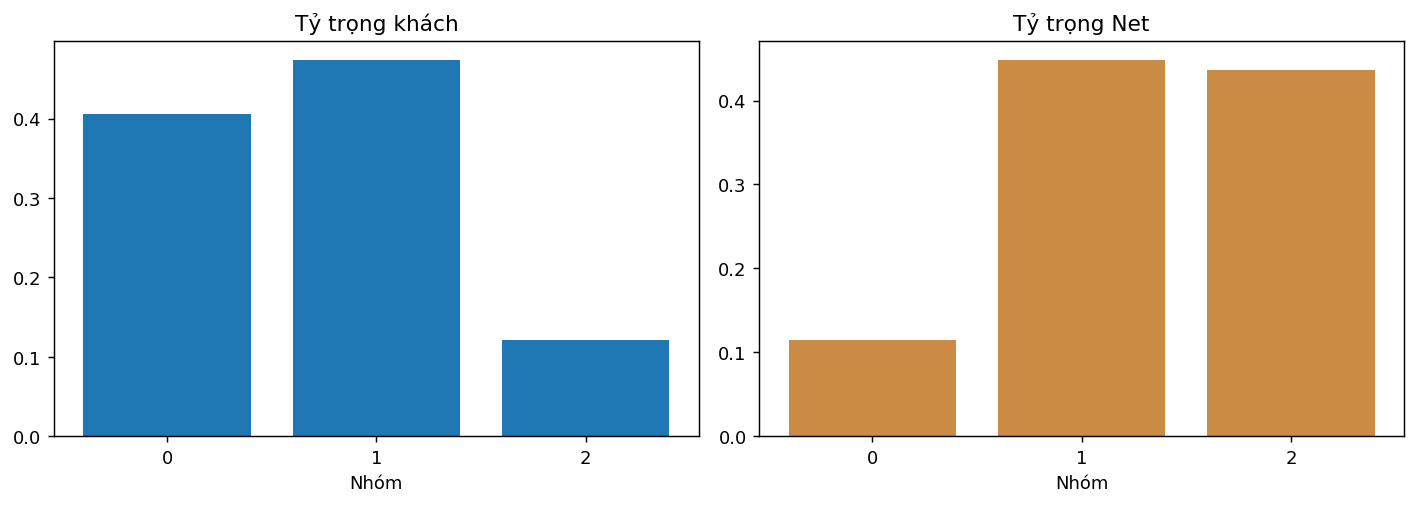

Tỷ trọng Net là giá trị delivered sau giảm tích lũy, không lợi nhuận hay thực thu. Không kết luận nhóm nhỏ là không quan trọng.

In [2]:
manifest=study.use_model(MODEL_LABEL);a=study.a.copy()
profiles=pd.read_csv(study.modelbase/'cluster_profiles.csv')
study.table('cluster_profiles','Hồ sơ gốc các nhóm',profiles)
fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].bar(profiles.cluster.astype(str),profiles.customer_share);axes[0].set(title='Tỷ trọng khách',xlabel='Nhóm');axes[1].bar(profiles.cluster.astype(str),profiles.Monetary_share,color='#ca8b45');axes[1].set(title='Tỷ trọng Net',xlabel='Nhóm');study.fig('cluster_shares','Quy mô và đóng góp nhóm',fig)
study.note('Tỷ trọng Net là giá trị delivered sau giảm tích lũy, không lợi nhuận hay thực thu. Không kết luận nhóm nhỏ là không quan trọng.')

## PC04.2 — Độ phân tán bên trong và vùng giao giữa nhóm

**Câu hỏi: các khách trong cùng cụm có hoàn toàn giống nhau không?**

Không. Xem các phân vị và boxplot để biết độ trải rộng bên trong. Khoảng từ phân vị 25% đến 75% (thường gọi là IQR) chứa phần giữa của dữ liệu; hai cụm có khoảng này chồng nhau trên một cột vẫn có thể khác nhau khi xét đồng thời ba cột.

Độ chồng lấn IQR không phải tỷ lệ khách bị gán sai. Một trung vị duy nhất không đủ đại diện mọi người trong nhóm. Nếu ẩn dấu ngoại lệ trên biểu đồ thì dữ liệu và mô hình vẫn giữ những khách đó.


,Nhóm,Đặc trưng,P10,P25,P50,P75,P90
0,0,Recency,1625.000,1826.0000,2307.000,2854.0000,3409.000
1,0,Frequency,1.000,1.0000,1.000,2.0000,4.000
2,0,Monetary,5468.304,12219.0275,29651.965,59104.2525,94502.225
3,1,Recency,127.000,258.0000,598.000,1002.0000,1320.000
4,1,Frequency,1.000,3.0000,5.000,8.0000,11.000
5,1,Monetary,25685.452,61872.6850,124473.995,205637.6175,275851.835
6,2,Recency,47.000,123.0000,244.000,509.0000,833.600
7,2,Frequency,14.000,16.0000,19.000,24.0000,32.000
8,2,Monetary,340576.674,393894.0000,477244.080,611022.6850,792823.720


C:\Users\trant\AppData\Local\Temp\ipykernel_27728\575216879.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  values=[g[col].astype(float).to_numpy() for _,g in a.groupby('cluster')];ax.boxplot(values,labels=[str(c) for c in sorted(a.cluster.unique())],showfliers=False);ax.set(title=col+' — không vẽ điểm ngoài box',xlabel='Nhóm')
C:\Users\trant\AppData\Local\Temp\ipykernel_27728\575216879.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  values=[g[col].astype(float).to_numpy() for _,g in a.groupby('cluster')];ax.boxplot(values,labels=[str(c) for c in sorted(a.cluster.unique())],showfliers=False);ax.set(title=col+' — không vẽ điểm ngoài box',xlabel='Nhóm')
C:\Users\trant\AppData\Local\Temp\ipykernel_27728\575216879.py:8: MatplotlibDeprec

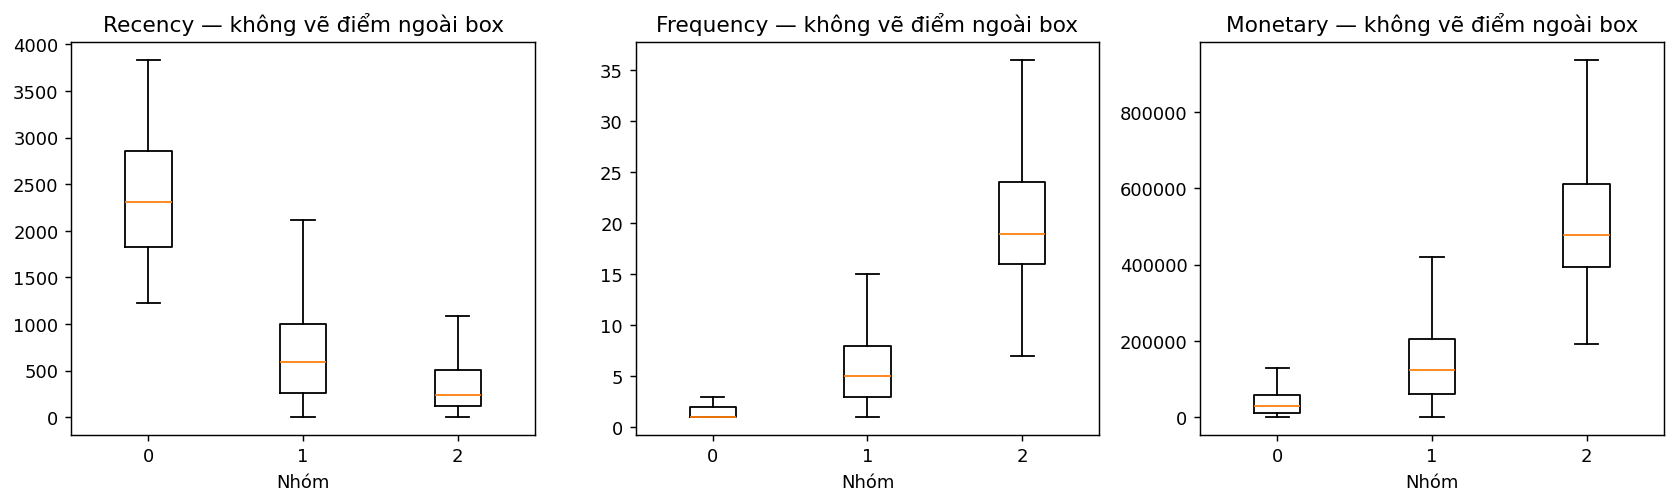

Nhóm không đồng nhất hoàn toàn. Cần đọc các biến đồng thời; ranh giới KMeans là khoảng cách đa biến trong không gian đã chuẩn hóa.

,Cặp nhóm,Đặc trưng,IQR trái dưới,IQR trái trên,IQR phải dưới,IQR phải trên,Độ dài giao IQR
0,0–1,Recency,1826.0000,2854.0000,258.000,1002.0000,0.0
1,0–1,Frequency,1.0000,2.0000,3.000,8.0000,0.0
2,0–1,Monetary,12219.0275,59104.2525,61872.685,205637.6175,0.0
3,0–2,Recency,1826.0000,2854.0000,123.000,509.0000,0.0
4,0–2,Frequency,1.0000,2.0000,16.000,24.0000,0.0
5,0–2,Monetary,12219.0275,59104.2525,393894.000,611022.6850,0.0
6,1–2,Recency,258.0000,1002.0000,123.000,509.0000,251.0
7,1–2,Frequency,3.0000,8.0000,16.000,24.0000,0.0
8,1–2,Monetary,61872.6850,205637.6175,393894.000,611022.6850,0.0


IQR giao theo một trục không phủ định phân tách đa biến; IQR không giao cũng không bảo đảm mọi khách của hai nhóm tách rời. Không biến độ dài giao thành tỷ lệ khách nhầm nhóm.

In [4]:
rows=[]
for cl,g in a.groupby('cluster'):
 for col in FEATURES:
  q=g[col].astype(float).quantile([.1,.25,.5,.75,.9]);rows.append({'cluster':cl,'Đặc trưng':col,'P10':q.loc[.1],'P25':q.loc[.25],'P50':q.loc[.5],'P75':q.loc[.75],'P90':q.loc[.9]})
quantiles=study.table('cluster_quantiles','Phân vị theo từng nhóm',pd.DataFrame(rows))
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,col in zip(axes,FEATURES):
 values=[g[col].astype(float).to_numpy() for _,g in a.groupby('cluster')];ax.boxplot(values,labels=[str(c) for c in sorted(a.cluster.unique())],showfliers=False);ax.set(title=col+' — không vẽ điểm ngoài box',xlabel='Nhóm')
study.fig('within_cluster_spread','Độ phân tán trong nhóm',fig)
study.note('Nhóm không đồng nhất hoàn toàn. Cần đọc các biến đồng thời; ranh giới KMeans là khoảng cách đa biến trong không gian đã chuẩn hóa.')
from itertools import combinations
intersection=[]
for left,right in combinations(sorted(a.cluster.unique()),2):
 for col in FEATURES:
  ql=a.loc[a.cluster.eq(left),col].astype(float).quantile([.25,.75]);qr=a.loc[a.cluster.eq(right),col].astype(float).quantile([.25,.75]);overlap=max(0,min(ql.iloc[1],qr.iloc[1])-max(ql.iloc[0],qr.iloc[0]))
  intersection.append({'Cặp nhóm':str(left)+'–'+str(right),'Đặc trưng':col,'IQR trái dưới':ql.iloc[0],'IQR trái trên':ql.iloc[1],'IQR phải dưới':qr.iloc[0],'IQR phải trên':qr.iloc[1],'Độ dài giao IQR':overlap})
study.table('marginal_iqr_overlap','Phần giao IQR từng trục giữa cặp nhóm',pd.DataFrame(intersection))
study.note('IQR giao theo một trục không phủ định phân tách đa biến; IQR không giao cũng không bảo đảm mọi khách của hai nhóm tách rời. Không biến độ dài giao thành tỷ lệ khách nhầm nhóm.')

## PC04.3 — Nhóm nào phân tách rõ, nhóm nào có nhiều trường hợp trung gian?

**Câu hỏi: nhóm nào tách rõ và nhóm nào có nhiều khách gần ranh giới?**

Tính Silhouette từng khách trong mẫu 5.000 rồi xem trung bình, trung vị và tỷ lệ âm theo nhóm. Cách tính đã giải thích ở PC03: điểm âm là dấu hiệu gần cụm khác hơn theo khoảng cách đang dùng, không phải nhãn sai đã được xác nhận.

Đọc phân bố bên cạnh hồ sơ RFM để hiểu trường hợp trung gian. Không lấy một trừ tỷ lệ âm làm độ chính xác. Kết quả chỉ trên mẫu đã chọn; khách gần ranh giới cần thận trọng khi gán chính sách rất khác nhau.


,Nhóm,sample_customers,silhouette_mean,silhouette_median,negative_share
0,0,2015,0.548810,0.611802,0.000000
1,1,2357,0.396373,0.448056,0.039881
2,2,628,0.405154,0.463920,0.019108


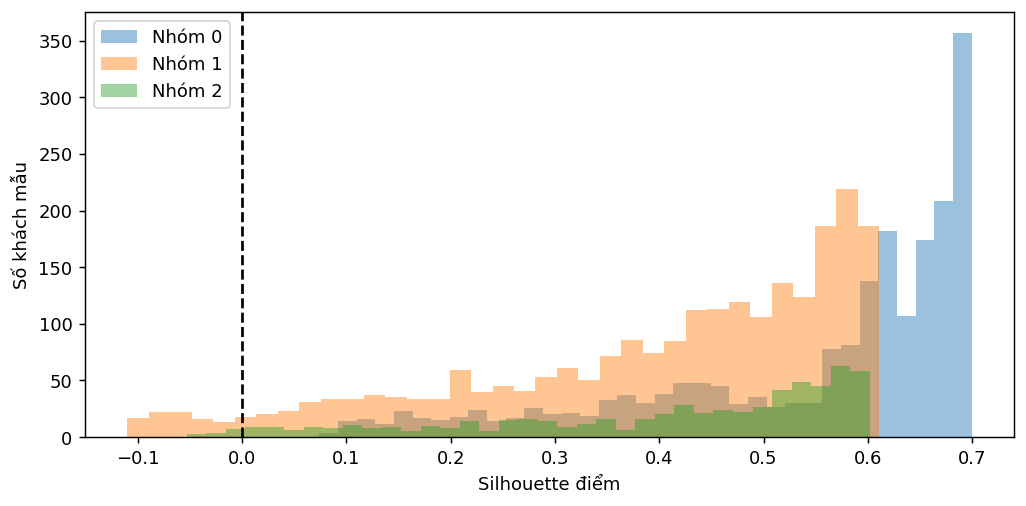

Tỷ lệ điểm mẫu silhouette âm=2.12%. Không gọi 1−tỷ lệ này là accuracy vì không có nhãn đúng.

In [5]:
from sklearn.metrics import silhouette_samples
from threadpoolctl import threadpool_limits
sample_ids=pd.read_csv(study.modelbase/'silhouette_sample.csv',dtype={'customer_id':str}).customer_id
s=a.set_index('customer_id').loc[sample_ids].reset_index();variant=manifest['selected']['variant']
x,sc=feature_matrix(a,variant);positions=pd.Index(a.customer_id).get_indexer(sample_ids)
with threadpool_limits(limits=1):ss=silhouette_samples(x[positions],s.cluster.to_numpy())
s['silhouette']=ss
q=s.groupby('cluster').agg(sample_customers=('customer_id','size'),silhouette_mean=('silhouette','mean'),silhouette_median=('silhouette','median'),negative_share=('silhouette',lambda v:(v<0).mean())).reset_index()
study.table('silhouette_by_cluster','Mức phân tách trên mẫu theo nhóm',q)
fig,ax=plt.subplots(figsize=(8,4))
for cl,g in s.groupby('cluster'):ax.hist(g.silhouette,bins=35,alpha=.45,label='Nhóm '+str(cl))
ax.axvline(0,color='black',linestyle='--');ax.set(xlabel='Silhouette điểm',ylabel='Số khách mẫu');ax.legend();study.fig('silhouette_distribution','Phần phân tách và khó phân biệt',fig)
study.note(f'Tỷ lệ điểm mẫu silhouette âm={np.mean(ss<0):.2%}. Không gọi 1−tỷ lệ này là accuracy vì không có nhãn đúng.')

## PC04.4 — Hủy/trả: hai trọng số và hai câu hỏi nghiệp vụ

**Câu hỏi: nhóm nào có hành vi hủy hoặc trả nhiều hơn?**

Phải xác định câu hỏi trước khi chọn cách tính. Trung bình tỷ lệ hủy từng khách coi mỗi khách có trọng số như nhau. Tổng đơn hủy chia tổng đơn trong nhóm coi mỗi đơn có trọng số như nhau, nên khách nhiều đơn ảnh hưởng lớn hơn.

Trung bình tỷ lệ theo khách và tỷ lệ gộp theo đơn trả lời hai câu hỏi khác nhau; không diễn giải tỷ lệ theo khách thành tỷ lệ trên tổng đơn.

Áp dụng cùng nguyên tắc cho returned. Bản ghi chi tiết hoàn trả khác nhãn returned nên báo riêng. Khác biệt mô tả chưa chứng minh gian lận, chất lượng khách hoặc nguyên nhân từ nhóm khách.


In [7]:
rows=[]
for cl,g in a.groupby('cluster'):
 rows.append({'cluster':cl,'Số khách':len(g),'TB tỷ trọng cancelled/khách':g.cancelled_share.mean(),'Tỷ trọng cancelled gộp đơn':g.cancelled_orders.sum()/g.total_orders.sum(),'TB tỷ trọng returned/khách':g.returned_share.mean(),'Tỷ trọng returned gộp đơn':g.returned_orders.sum()/g.total_orders.sum(),'Khách có đơn thiếu shipment':int(g.delivered_missing_shipment_share.gt(0).sum()),'TB thiếu shipment/khách':g.delivered_missing_shipment_share.mean()})
behavior=study.table('behavior_denominators','Hai mẫu số và cờ theo nhóm',pd.DataFrame(rows))
study.note('Khách mua nhiều có nhiều cơ hội ghi nhận hủy/trả. Tỷ trọng cao hơn chưa chứng minh nhóm kém chất lượng, gian lận hoặc nguyên nhân đến từ khách.')
mean_order=behavior.sort_values('TB tỷ trọng cancelled/khách').cluster.astype(int).tolist()
pooled_order=behavior.sort_values('Tỷ trọng cancelled gộp đơn').cluster.astype(int).tolist()
study.note(f'Thứ tự nhóm theo cancelled tăng dần: trung bình theo khách={mean_order}; gộp theo đơn={pooled_order}. Hai thứ tự khác nhau cho thấy kết luận “nhóm hủy nhiều nhất” phụ thuộc câu hỏi và mẫu số; không chọn một mẫu số sau khi thấy kết quả thuận lợi.')

,Nhóm,Số khách,TB tỷ trọng cancelled/khách,Tỷ trọng cancelled gộp đơn,TB tỷ trọng returned/khách,Tỷ trọng returned gộp đơn,Khách có đơn thiếu shipment,TB thiếu shipment/khách
0,0,34498,0.061616,0.094139,0.036944,0.056711,0,0.000000
1,1,40342,0.075082,0.090031,0.045350,0.054373,305,0.001875
2,2,10275,0.082397,0.085554,0.050480,0.052306,208,0.000975


Khách mua nhiều có nhiều cơ hội ghi nhận hủy/trả. Tỷ trọng cao hơn chưa chứng minh nhóm kém chất lượng, gian lận hoặc nguyên nhân đến từ khách.

Thứ tự nhóm theo cancelled tăng dần: trung bình theo khách=[0, 1, 2]; gộp theo đơn=[2, 1, 0]. Hai thứ tự khác nhau cho thấy kết luận “nhóm hủy nhiều nhất” phụ thuộc câu hỏi và mẫu số; không chọn một mẫu số sau khi thấy kết quả thuận lợi.

## PC04.5 — Giỏ hàng, độ rộng giao dịch và tập trung nội bộ

**Câu hỏi: các nhóm khác nhau về giỏ hàng và sự tập trung giá trị như thế nào?**

Giá trị đơn trung bình là Monetary chia số đơn delivered. Số lượng mỗi đơn lấy tổng số lượng hàng delivered chia số đơn delivered. Độ rộng giao dịch đếm các sản phẩm khác nhau đã mua, không đếm lặp cùng sản phẩm thành nhiều loại.

Xem thêm nhóm 10% khách Monetary cao nhất bên trong từng cụm đóng góp bao nhiêu tổng tiền của cụm. Chỉ tiêu này cho biết cụm có bị một ít khách chi phối không. Khách nhiều đơn có nhiều cơ hội mua nhiều loại; chưa thể suy họ thích đa dạng hoặc nhạy giá.


In [8]:
rows=[]
for cl,g in a.groupby('cluster'):
 top=concentration(g).loc[lambda d:d.top_customer_fraction.eq(.1),'monetary_share'].iloc[0]
 rows.append({'cluster':cl,'AOV trung vị':g.average_order_value.median(),'Số lượng/đơn trung vị':g.units_per_delivered_order.median(),'Số sản phẩm khác nhau trung vị':g.distinct_products.median(),'Tỷ trọng Net top10% trong nhóm':top})
study.table('basket_and_concentration','Giỏ hàng và tập trung nội bộ',pd.DataFrame(rows))
study.note('AOV=M/F phụ thuộc RFM; breadth tăng theo số cơ hội mua. Chưa thể gọi là sở thích đa dạng hoặc nhạy giá nếu thiếu kiểm soát tần suất/cơ hội.')

,Nhóm,AOV trung vị,Số lượng/đơn trung vị,Số sản phẩm khác nhau trung vị,Tỷ trọng Net top10% trong nhóm
0,0,17688.128333,5.000000,2.0,0.314164
1,1,23026.396250,4.857143,6.0,0.228045
2,2,25324.892222,5.038462,20.0,0.187857


AOV=M/F phụ thuộc RFM; breadth tăng theo số cơ hội mua. Chưa thể gọi là sở thích đa dạng hoặc nhạy giá nếu thiếu kiểm soát tần suất/cơ hội.

## PC04.6 — Cơ cấu danh mục: kiểm mạch kể bằng dữ liệu giao dịch

**Câu hỏi: cơ cấu sản phẩm có giúp mô tả các nhóm rõ hơn không?**

Ghép nhãn khách với các đơn delivered, sau đó với dòng hàng theo quan hệ đã kiểm chứng. Trong mỗi nhóm, đọc tỷ trọng số lượng và tỷ trọng Net của từng danh mục. Tổng tiền danh mục phải khớp Monetary của khách, tránh nhân hoặc mất tiền khi ghép.

Danh mục sản phẩm là thông tin hiện có trong bảng, chưa xác nhận lịch sử thay đổi danh mục. Khác biệt giữa nhóm là mô tả giao dịch; không tự chứng minh sở thích cố định hoặc tác dụng của khuyến mãi.


In [9]:
o=study.orders();keys=o.loc[o.order_status.eq('delivered') & o.order_date.le(CUTOFF),['order_id','customer_id']].merge(a[['customer_id','cluster']],on='customer_id',validate='many_to_one')
items=pd.read_csv(ROOT/'data/processed/order_items_common.csv',dtype=str,usecols=['order_id','quantity','category','line_net'],keep_default_na=False)
joined=items.merge(keys,on='order_id',how='inner',validate='many_to_one');joined['quantity']=pd.to_numeric(joined.quantity);joined['line_net']=joined.line_net.map(Decimal)
cat=joined.groupby(['cluster','category']).agg(units=('quantity','sum'),net=('line_net',lambda x:sum(x,Decimal(0)))).reset_index();cat['net']=cat.net.astype(float);cat['units_share_in_cluster']=cat.units/cat.groupby('cluster').units.transform('sum');cat['net_share_in_cluster']=cat.net/cat.groupby('cluster').net.transform('sum')
require(np.isclose(cat.net.sum(),a.Monetary.sum()),'Mất/nhân tiền khi JOIN dòng hàng')
study.table('category_mix','Cơ cấu danh mục theo nhóm',cat)
study.note('Danh mục common dùng thông tin danh mục hiện có; hiệu lực lịch sử chưa xác minh. Khác biệt cơ cấu là mô tả giao dịch, không chứng minh sở thích cố định hay tác động marketing.')

,Nhóm,category,units,net,units_share_in_cluster,net_share_in_cluster
0,0,Casual,9588,3.511574e+07,0.029288,0.024467
1,0,GenZ,15731,3.107925e+07,0.048053,0.021655
2,0,Outdoor,133164,2.373434e+08,0.406774,0.165372
3,0,Streetwear,168883,1.131670e+09,0.515884,0.788506
4,1,Casual,39306,1.601167e+08,0.034451,0.028517
5,1,GenZ,68055,1.341207e+08,0.059648,0.023887
6,1,Outdoor,387498,7.577168e+08,0.339632,0.134948
7,1,Streetwear,646077,4.562920e+09,0.566269,0.812649
8,2,Casual,36563,1.538618e+08,0.033311,0.028138
9,2,GenZ,49469,9.800342e+07,0.045069,0.017923


Danh mục common dùng thông tin danh mục hiện có; hiệu lực lịch sử chưa xác minh. Khác biệt cơ cấu là mô tả giao dịch, không chứng minh sở thích cố định hay tác động marketing.

## PC04.7 — So sánh k=2,3,4 bằng cấu trúc khách thực tế

**Câu hỏi: chọn ba cụm giúp hiểu thêm gì so với hai hoặc bốn cụm?**

Giữ cùng cách biểu diễn và xem hồ sơ khách khi chia hai, ba, bốn cụm. Bảng chéo cho biết khách trong mỗi nhóm của phương án trước phân bố sang những nhóm nào ở phương án sau.

K-Means tối ưu lại ranh giới khi đổi số cụm, nên ba cụm không nhất thiết chỉ là tách đôi một nhóm của hai cụm. Không đọc các ô ngoài đường chéo như tỷ lệ đổi nhãn vì số nhóm và mã nhãn không tương ứng.

Phần chi tiết thêm đáng giữ khi có hồ sơ khác biệt và câu hỏi sử dụng rõ. Nếu bốn cụm chỉ chia nhỏ nhóm đuôi mà chưa có mục tiêu riêng, không mặc định nó tốt hơn ba cụm.


In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
with threadpool_limits(limits=1):
 labels_by_k={k:KMeans(n_clusters=k,n_init=10,random_state=42,max_iter=300).fit_predict(x) for k in [2,3,4]}
require(adjusted_rand_score(labels_by_k[manifest['selected']['k']],a.cluster)==1,'Không tái lập được phân hoạch')
for k,labels in labels_by_k.items():
 means=a.assign(raw_label=labels).groupby('raw_label').Monetary.mean().sort_values();mapping={old:new for new,old in enumerate(means.index)};a['k'+str(k)]=pd.Series(labels).map(mapping).to_numpy()
ct23=pd.crosstab(a.k2,a.k3).reset_index();ct34=pd.crosstab(a.k3,a.k4).reset_index()
study.table('k2_to_k3','Phân bố khách từ k2 sang k3 — không là tỷ lệ đổi nhãn',ct23)
study.table('k3_to_k4','Phân bố khách từ k3 sang k4 — không là tỷ lệ đổi nhãn',ct34)
for k in [2,3,4]:study.table('profile_k'+str(k),'Hồ sơ cùng thí nghiệm k='+str(k),share_table(a,'k'+str(k)))
study.note('Bảng chéo cho biết cụm nào bị chia/gộp. Không chỉ nhìn ô ngoài đường chéo vì số cụm khác và nhãn không tương ứng. k3 chỉ đáng chọn nếu phần tách thêm có hồ sơ/cách sử dụng rõ; k4 có thể chia nhỏ đuôi nhưng tăng độ phức tạp.')
count23=pd.crosstab(a.k2,a.k3)
if 1 in count23.columns and 0 in count23.index and 1 in count23.index:
 study.note(f'Ở dữ liệu này, nhóm giữa của k3 nhận {int(count23.loc[0,1]):,} khách từ nhóm M thấp của k2 và {int(count23.loc[1,1]):,} từ nhóm M cao của k2. KMeans k3 không chỉ cắt một nhóm k2 thành hai: ranh giới được tối ưu lại. Do đó không diễn giải như cây phân cấp.')
k4profiles=share_table(a,'k4');small=k4profiles.loc[k4profiles.customer_share.idxmin()]
study.note(f'k4 có nhóm nhỏ nhất {int(small.customers):,} khách ({small.customer_share:.2%}), trung vị F={small.Frequency_median:.0f}, M={small.Monetary_median:,.2f}. Tách chi tiết này chỉ hữu ích khi có mục tiêu sử dụng riêng; chưa có bằng chứng hiệu quả để bắt buộc chọn k4.')

k3,k2,0,1,2
0,0,34498,31678,0
1,1,0,8664,10275


k4,k3,0,1,2,3
0,0,31101,3394,3,0
1,1,19,30896,9427,0
2,2,0,0,6510,3765


,k2,Số khách,Tổng Net,R trung vị,F trung vị,M trung vị,Tỷ trọng khách,Tỷ trọng Net
0,0,66176,4.724247e+09,1592.0,2.0,52773.19,0.777489,0.377391
1,1,18939,7.793929e+09,271.0,14.0,354134.31,0.222511,0.622609


,k3,Số khách,Tổng Net,R trung vị,F trung vị,M trung vị,Tỷ trọng khách,Tỷ trọng Net
0,0,34498,1.435208e+09,2307.0,1.0,29651.965,0.405310,0.114650
1,1,40342,5.614874e+09,598.0,5.0,124473.995,0.473971,0.448538
2,2,10275,5.468093e+09,244.0,19.0,477244.080,0.120719,0.436812


,k4,Số khách,Tổng Net,R trung vị,F trung vị,M trung vị,Tỷ trọng khách,Tỷ trọng Net
0,0,31120,1.246149e+09,2390.0,1.0,28113.80,0.365623,0.099547
1,1,34290,3.285359e+09,747.0,4.0,88140.73,0.402867,0.262447
2,2,15940,5.247734e+09,328.0,12.0,312238.31,0.187276,0.419209
3,3,3765,2.738934e+09,191.0,27.0,674514.02,0.044234,0.218797


Bảng chéo cho biết cụm nào bị chia/gộp. Không chỉ nhìn ô ngoài đường chéo vì số cụm khác và nhãn không tương ứng. k3 chỉ đáng chọn nếu phần tách thêm có hồ sơ/cách sử dụng rõ; k4 có thể chia nhỏ đuôi nhưng tăng độ phức tạp.

Ở dữ liệu này, nhóm giữa của k3 nhận 31,678 khách từ nhóm M thấp của k2 và 8,664 từ nhóm M cao của k2. KMeans k3 không chỉ cắt một nhóm k2 thành hai: ranh giới được tối ưu lại. Do đó không diễn giải như cây phân cấp.

k4 có nhóm nhỏ nhất 3,765 khách (4.42%), trung vị F=27, M=674,514.02. Tách chi tiết này chỉ hữu ích khi có mục tiêu sử dụng riêng; chưa có bằng chứng hiệu quả để bắt buộc chọn k4.

## PC04.8 — Từ phát hiện đến giả thuyết hành động có điều kiện

**Câu hỏi: từ bảng mô tả có thể đề xuất hành động gì?**

Với mỗi phát hiện, ghi rõ số liệu hỗ trợ, giới hạn và điều cần xác minh trước hành động. Khách mua nhiều có thể đáng nghiên cứu duy trì trải nghiệm; khách lâu chưa mua có thể cần tìm hiểu nhu cầu quay lại. Đó là hướng thử nghiệm, chưa là kết luận ưu đãi sẽ hiệu quả.

Tên nhóm dựa đồng thời mức ngày chưa mua, số đơn và giá trị tích lũy. Không gán VIP, rời bỏ hoặc CLV cao khi chưa có định nghĩa và dữ liệu cần thiết. PC05 kiểm độ nhạy và PC06 đưa ra thiết kế đo hiệu quả.


In [11]:
findings=[]
for cl,g in a.groupby('cluster'):
 row=profiles.set_index('cluster').loc[cl]
 findings.append({'Mã':'PCF-'+str(int(cl)+1).zfill(2),'Phát hiện':f'Nhóm {cl}: {len(g):,} khách, R trung vị {g.Recency.median():.0f}, F {g.Frequency.median():.0f}, M {g.Monetary.median():,.2f}; tỷ trọng Net {row.Monetary_share:.2%}.','Bằng chứng':'cluster_profiles + cluster_quantiles + behavior_denominators','Giới hạn':'R/F/M lịch sử delivered; chưa CLV/churn/nhân quả','Hướng xem xét':'Đọc độ nhạy PC05; xác minh nghiệp vụ trước hành động'})
study.table('findings','Các phát hiện truy vết',pd.DataFrame(findings))
study.note('Bàn giao PC05: đánh giá k3 với đối thủ k2/k4, độ nhạy trạng thái và giới hạn. Có thể giữ k2 nếu mục tiêu chỉ là hai mức đóng góp; chưa có một k đúng cho mọi mục tiêu.')
extra=pd.DataFrame([
{'Mã':'PCF-04','Phát hiện':f'Trong mẫu5000, {(ss<0).sum():,} điểm ({(ss<0).mean():.2%}) có silhouette âm; cần xem ranh giới, không gọi là sai nhãn.','Bằng chứng':'silhouette_by_cluster + mẫu cố định','Giới hạn':'Không có nhãn đúng; mẫu dùng lựa chọn','Hướng xem xét':'Thận trọng khi hành động trên khách gần ranh giới'},
{'Mã':'PCF-05','Phát hiện':'Thứ tự tỷ trọng hủy theo nhóm thay đổi giữa trung bình khách và gộp đơn.','Bằng chứng':'behavior_denominators','Giới hạn':'Hai mẫu số trả lời hai câu hỏi; snapshot không là ý định','Hướng xem xét':'Ghi rõ mẫu số trong mọi bảng và kết luận'},
{'Mã':'PCF-06','Phát hiện':'k3 tạo nhóm giữa từ cả hai nhóm k2; k4 tách thêm vùng giá trị cao.','Bằng chứng':'k2_to_k3 + k3_to_k4 + hồ sơ k2/3/4','Giới hạn':'Không phải phân cấp hay bằng chứng tối ưu kinh doanh','Hướng xem xét':'Giữ k3 cho mô tả ba mức, k2/k4 làm đối thủ có điều kiện'}])
study.table('cross_group_findings','Phát hiện liên nhóm và đối chiếu ứng viên',extra);


,Mã,Phát hiện,Bằng chứng,Giới hạn,Hướng xem xét
0,PCF-01,"Nhóm 0: 34,498 khách, R trung vị 2307, F 1, M ...",cluster_profiles + cluster_quantiles + behavio...,R/F/M lịch sử delivered; chưa CLV/churn/nhân quả,Đọc độ nhạy PC05; xác minh nghiệp vụ trước hàn...
1,PCF-02,"Nhóm 1: 40,342 khách, R trung vị 598, F 5, M 1...",cluster_profiles + cluster_quantiles + behavio...,R/F/M lịch sử delivered; chưa CLV/churn/nhân quả,Đọc độ nhạy PC05; xác minh nghiệp vụ trước hàn...
2,PCF-03,"Nhóm 2: 10,275 khách, R trung vị 244, F 19, M ...",cluster_profiles + cluster_quantiles + behavio...,R/F/M lịch sử delivered; chưa CLV/churn/nhân quả,Đọc độ nhạy PC05; xác minh nghiệp vụ trước hàn...


Bàn giao PC05: đánh giá k3 với đối thủ k2/k4, độ nhạy trạng thái và giới hạn. Có thể giữ k2 nếu mục tiêu chỉ là hai mức đóng góp; chưa có một k đúng cho mọi mục tiêu.

,Mã,Phát hiện,Bằng chứng,Giới hạn,Hướng xem xét
0,PCF-04,"Trong mẫu5000, 106 điểm (2.12%) có silhouette ...",silhouette_by_cluster + mẫu cố định,Không có nhãn đúng; mẫu dùng lựa chọn,Thận trọng khi hành động trên khách gần ranh giới
1,PCF-05,Thứ tự tỷ trọng hủy theo nhóm thay đổi giữa tr...,behavior_denominators,Hai mẫu số trả lời hai câu hỏi; snapshot không...,Ghi rõ mẫu số trong mọi bảng và kết luận
2,PCF-06,k3 tạo nhóm giữa từ cả hai nhóm k2; k4 tách th...,k2_to_k3 + k3_to_k4 + hồ sơ k2/3/4,Không phải phân cấp hay bằng chứng tối ưu kinh...,"Giữ k3 cho mô tả ba mức, k2/k4 làm đối thủ có ..."


### Đề xuất KPI để kiểm nghiệm hành động

Các KPI là kế hoạch đo khi có chương trình thực tế: tỷ lệ mua lại, số đơn và Net trên mỗi khách đủ điều kiện, chi phí và mức chênh so với nhóm đối chứng. Chốt kỳ đo, phạm vi khách và cách tính trước khi chạy. PC06 giải thích thiết kế 60 ngày; không có kết quả tác động thực tế trong bộ dữ liệu này.


## Tổng kết nghiệp vụ và điều kiện bàn giao

Các đoạn dưới được sinh từ kết quả thật của phần phân tích, giữ riêng quan sát và giả thuyết.

In [12]:
study.note("### Hồ sơ mô tả và chương trình nghiên cứu hành động")
t=study.a;reference=t[['Recency','Frequency','Monetary']].median();group_medians=t.groupby('cluster')[['Recency','Frequency','Monetary']].median();actions=[]
for cl,g in t.groupby('cluster'):
 R,F,M=g.Recency.median(),g.Frequency.median(),g.Monetary.median()
 if R==group_medians.Recency.max() and F==group_medians.Frequency.min():
  label='Ít đơn, lâu chưa có đơn delivered';objective='Tìm hiểu khoảng ngừng mua quan sát được';hypothesis='Nghiên cứu nhu cầu quay lại, chưa gán churn'
 elif F==group_medians.Frequency.max() and M==group_medians.Monetary.max():
  label='Mua lặp lại nhiều, giá trị tích lũy cao hơn';objective='Nghiên cứu duy trì tần suất và trải nghiệm';hypothesis='Chưa gọi VIP/CLV cao khi thiếu chi phí và tương lai'
 else:
  label='Mức hoạt động và giá trị trung gian trong tập';objective='Tìm hiểu cơ hội mua tiếp phù hợp chu kỳ';hypothesis='Chưa có bằng chứng ưu đãi sẽ tăng mua'
 study.note(f'**Nhóm{cl} — {label}:** trung vị R={R:.0f} ngày, F={F:.0f} đơn, M={M:,.2f} ĐVT nguồn. Tên mô tả dựa đồng thời ba trục so với toàn tập, không phải nhãn chuẩn có sẵn. Đọc thêm khoảng phân vị và tỷ lệ hủy/trả trước hành động.')
 actions.append({'cluster':cl,'Tên mô tả đề xuất':label,'Câu hỏi sử dụng':objective,'Giới hạn':hypothesis,'Bằng chứng cần bổ sung':'Chu kỳ mua, chi phí/biên hàng, định nghĩa sự kiện và thiết kế đánh giá có đối chứng'})
study.table('business_action_hypotheses','Đề xuất theo nhóm: mục tiêu và điều kiện, chưa là hiệu quả đã đạt',pd.DataFrame(actions));


### Hồ sơ mô tả và chương trình nghiên cứu hành động

**Nhóm0 — Ít đơn, lâu chưa có đơn delivered:** trung vị R=2307 ngày, F=1 đơn, M=29,651.97 ĐVT nguồn. Tên mô tả dựa đồng thời ba trục so với toàn tập, không phải nhãn chuẩn có sẵn. Đọc thêm khoảng phân vị và tỷ lệ hủy/trả trước hành động.

**Nhóm1 — Mức hoạt động và giá trị trung gian trong tập:** trung vị R=598 ngày, F=5 đơn, M=124,473.99 ĐVT nguồn. Tên mô tả dựa đồng thời ba trục so với toàn tập, không phải nhãn chuẩn có sẵn. Đọc thêm khoảng phân vị và tỷ lệ hủy/trả trước hành động.

**Nhóm2 — Mua lặp lại nhiều, giá trị tích lũy cao hơn:** trung vị R=244 ngày, F=19 đơn, M=477,244.08 ĐVT nguồn. Tên mô tả dựa đồng thời ba trục so với toàn tập, không phải nhãn chuẩn có sẵn. Đọc thêm khoảng phân vị và tỷ lệ hủy/trả trước hành động.

,Nhóm,Tên mô tả đề xuất,Câu hỏi sử dụng,Giới hạn,Bằng chứng cần bổ sung
0,0,"Ít đơn, lâu chưa có đơn delivered",Tìm hiểu khoảng ngừng mua quan sát được,"Nghiên cứu nhu cầu quay lại, chưa gán churn","Chu kỳ mua, chi phí/biên hàng, định nghĩa sự k..."
1,1,Mức hoạt động và giá trị trung gian trong tập,Tìm hiểu cơ hội mua tiếp phù hợp chu kỳ,Chưa có bằng chứng ưu đãi sẽ tăng mua,"Chu kỳ mua, chi phí/biên hàng, định nghĩa sự k..."
2,2,"Mua lặp lại nhiều, giá trị tích lũy cao hơn",Nghiên cứu duy trì tần suất và trải nghiệm,Chưa gọi VIP/CLV cao khi thiếu chi phí và tươn...,"Chu kỳ mua, chi phí/biên hàng, định nghĩa sự k..."


## Kiểm chứng và hoàn tất phân tích

Đối soát trực tiếp nguồn, kiểm nguồn không thay đổi trong phiên và hoàn tất phân tích. Bảng/biểu đồ hiển thị trong notebook. Chỉ CSV phân cụm cuối được lưu; không đọc hoặc xuất JSON. Tính lại khi mở kernel mới, không dùng kết quả cũ làm đầu vào.


In [13]:
part_manifest=study.finish()

## Tài liệu phương pháp và phạm vi tham khảo

- [scikit-learn: K-Means và tổng quan phân cụm](https://scikit-learn.org/stable/modules/clustering.html#k-means).
- [StandardScaler: công thức và quy ước phương sai](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).
- [Silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).
- [Davies–Bouldin](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.davies_bouldin_score.html).
- [Adjusted Rand Index](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html).

Các nguồn trên giải thích phương pháp chung; không xác nhận ngữ nghĩa status/payment/delivery_date của bộ dữ liệu. Những định nghĩa nghiệp vụ dự án kế thừa hợp đồng GD2 và quyết định phạm vi đã công bố. Tên phiên bản thư viện chạy thực tế được hiển thị trong notebook, không suy từ phiên bản trang tài liệu hiện hành.
